# Cost-Aware Industry Momentum Research
AlphaLab Sprint v1 · read-only display of accepted results

**Owner-authorized complete research presentation.** Project implementation, analysis and calculated outputs are included; source datasets are excluded, and no general third-party redistribution grant or additional software license is claimed. Does ranking 49 industries by past momentum improve on an equal-weight benchmark after costs and a fixed risk rule? This notebook displays accepted summaries and labeled synthetic examples; it does not run research. [Full report](../reports/final_report.md) · [README](../README.md) · [Rights](../docs/RIGHTS_STATUS.md)


## Fixed samples and an already observed final test

| Interval | Role |
|---|---|
| 1998–1999 | Warmup; historical base portfolio returns begin in 1999 |
| 2000–2017 | Research, 216 months |
| 2018–2023 | Validation, 72 months |
| 2024–2025 | Final evaluation, 24 months; **already observed** |

**OOS OBSERVED UNDER HQ-D5-001.** There were two historical formal runs: the original evaluation and one identical repeat, not two independent samples. This notebook only reads accepted summaries and a saved figure. It never reads raw/processed financial inputs or calls the production package. All teaching examples below are separate from project results.


In [1]:
from pathlib import Path
import csv
import hashlib
import io
import json
import os
from html import escape
from IPython.display import display, HTML, Image

# Optional ALPHALAB_ROOT; otherwise search cwd and its ancestors deterministically.
candidate = os.environ.get("ALPHALAB_ROOT")
roots = [Path(candidate).expanduser().resolve()] if candidate else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in roots if (p / "PROJECT_SPEC.md").is_file()), None)
if ROOT is None:
    raise RuntimeError("Project root not found. Start in notebooks/ or set ALPHALAB_ROOT.")

ANCHORS = {
    "outputs/day4/run_manifest.json": "8e3f587d0aa1f575fd18f920264aaeea38a0064257cabd9ee047a223665da461",
    "outputs/day5/run_manifest.json": "2fef4ac6f524291898dafa4e7febe405eaa5369bb3a7a6ac741f0a71f87b6998",
    "reports/figures/day6_release/presentation_manifest.json": "af87d049d9046aa9a14838bd0f31f9b1de78bbd1c33e3ead782d5e5f0105a5b4",
}
VERIFIED = {}
def checked_bytes(relative, expected):
    path = ROOT / relative
    if not path.is_file():
        raise RuntimeError("Missing accepted file: " + relative + "; no download or computation is attempted.")
    raw = path.read_bytes()
    actual = hashlib.sha256(raw).hexdigest()
    if actual != expected:
        raise RuntimeError("SHA-256 mismatch: " + relative + "; execution stopped.")
    VERIFIED[relative] = actual
    return raw

MANIFESTS = {p: json.loads(checked_bytes(p, h)) for p, h in ANCHORS.items()}
def accepted_csv(day, name):
    manifest = MANIFESTS[f"outputs/{day}/run_manifest.json"]
    raw = checked_bytes(f"outputs/{day}/{name}", manifest["outputs"][name]["sha256"])
    return list(csv.DictReader(io.StringIO(raw.decode("utf-8"))))

def table(headers, rows):
    body = "<table><thead><tr>" + "".join("<th>" + escape(str(v)) + "</th>" for v in headers) + "</tr></thead><tbody>"
    for row in rows:
        body += "<tr>" + "".join("<td>" + escape(str(v)) + "</td>" for v in row) + "</tr>"
    display(HTML(body + "</tbody></table>"))

def pct(value):
    return f"{float(value) * 100:.4f}%"
print("Three public display derivative manifests verified. Paths below are project-relative.")


Three public display derivative manifests verified. Paths below are project-relative.


## Accepted results — real project output, not a new calculation

Main cost: **10 bps per purchase or sale**. CAGR, segment-local maximum drawdown and mean industry exposure below are stored summary fields, only formatted as percentages. Capital and holdings continue across sample boundaries; each segment's metrics use its own initial wealth.

MOM5 selects five industries; EW49 is the broad equal-weight benchmark. Their VOL10 versions use their own past base portfolio returns and hold residual cash. [All 12 OOS scenarios](../outputs/day5/performance_summary.csv) · [Research/validation and fixed subperiods](../outputs/day4/performance_summary.csv)


In [2]:
STRATEGIES = ["MOM5", "EW49", "MOM5_VOL10", "EW49_VOL10"]
performance = accepted_csv("day4", "performance_summary.csv") + accepted_csv("day5", "performance_summary.csv")
real_performance_rows = []
for segment in ["research", "validation", "oos"]:
    for strategy in STRATEGIES:
        matches = [r for r in performance if r["segment"] == segment and r["strategy"] == strategy and r["cost_bps"] == "10"]
        if len(matches) != 1:
            raise RuntimeError("Expected one accepted summary per segment and strategy.")
        row = matches[0]
        real_performance_rows.append([segment, strategy, row["months"], pct(row["cagr"]), pct(row["max_drawdown"]), pct(row["mean_risky_weight"])])
table(["Segment", "Portfolio", "Months", "CAGR", "Max drawdown", "Mean industry exposure"], real_performance_rows)


Segment,Portfolio,Months,CAGR,Max drawdown,Mean industry exposure
research,MOM5,216,10.1336%,60.8051%,100.0000%
research,EW49,216,9.4088%,52.6636%,100.0000%
research,MOM5_VOL10,216,8.8146%,25.6154%,57.2935%
research,EW49_VOL10,216,6.9669%,35.5417%,75.2983%
validation,MOM5,72,20.1018%,22.9645%,100.0000%
validation,EW49,72,10.1627%,25.9482%,100.0000%
validation,MOM5_VOL10,72,8.4651%,18.1904%,52.5945%
validation,EW49_VOL10,72,3.1338%,17.7624%,60.2218%
oos,MOM5,24,5.0438%,10.7026%,100.0000%
oos,EW49,24,15.3700%,9.4698%,100.0000%


## Read the full path without treating it as a new holdout

The final interval favored EW49 over MOM5, and EW49_VOL10 over MOM5_VOL10. Lower exposure and drawdown are not evidence of alpha. No parameter was changed to rescue the result.

The **existing accepted figure** starts at wealth 1 in December 1999, carries capital through 2018/2024, and uses a log wealth axis. Its negative drawdown panel uses continuous historical peaks; the table above reports nonnegative **segment-local** maximum losses. The full 2000–2025 display is retrospective, not one independent out-of-sample test.


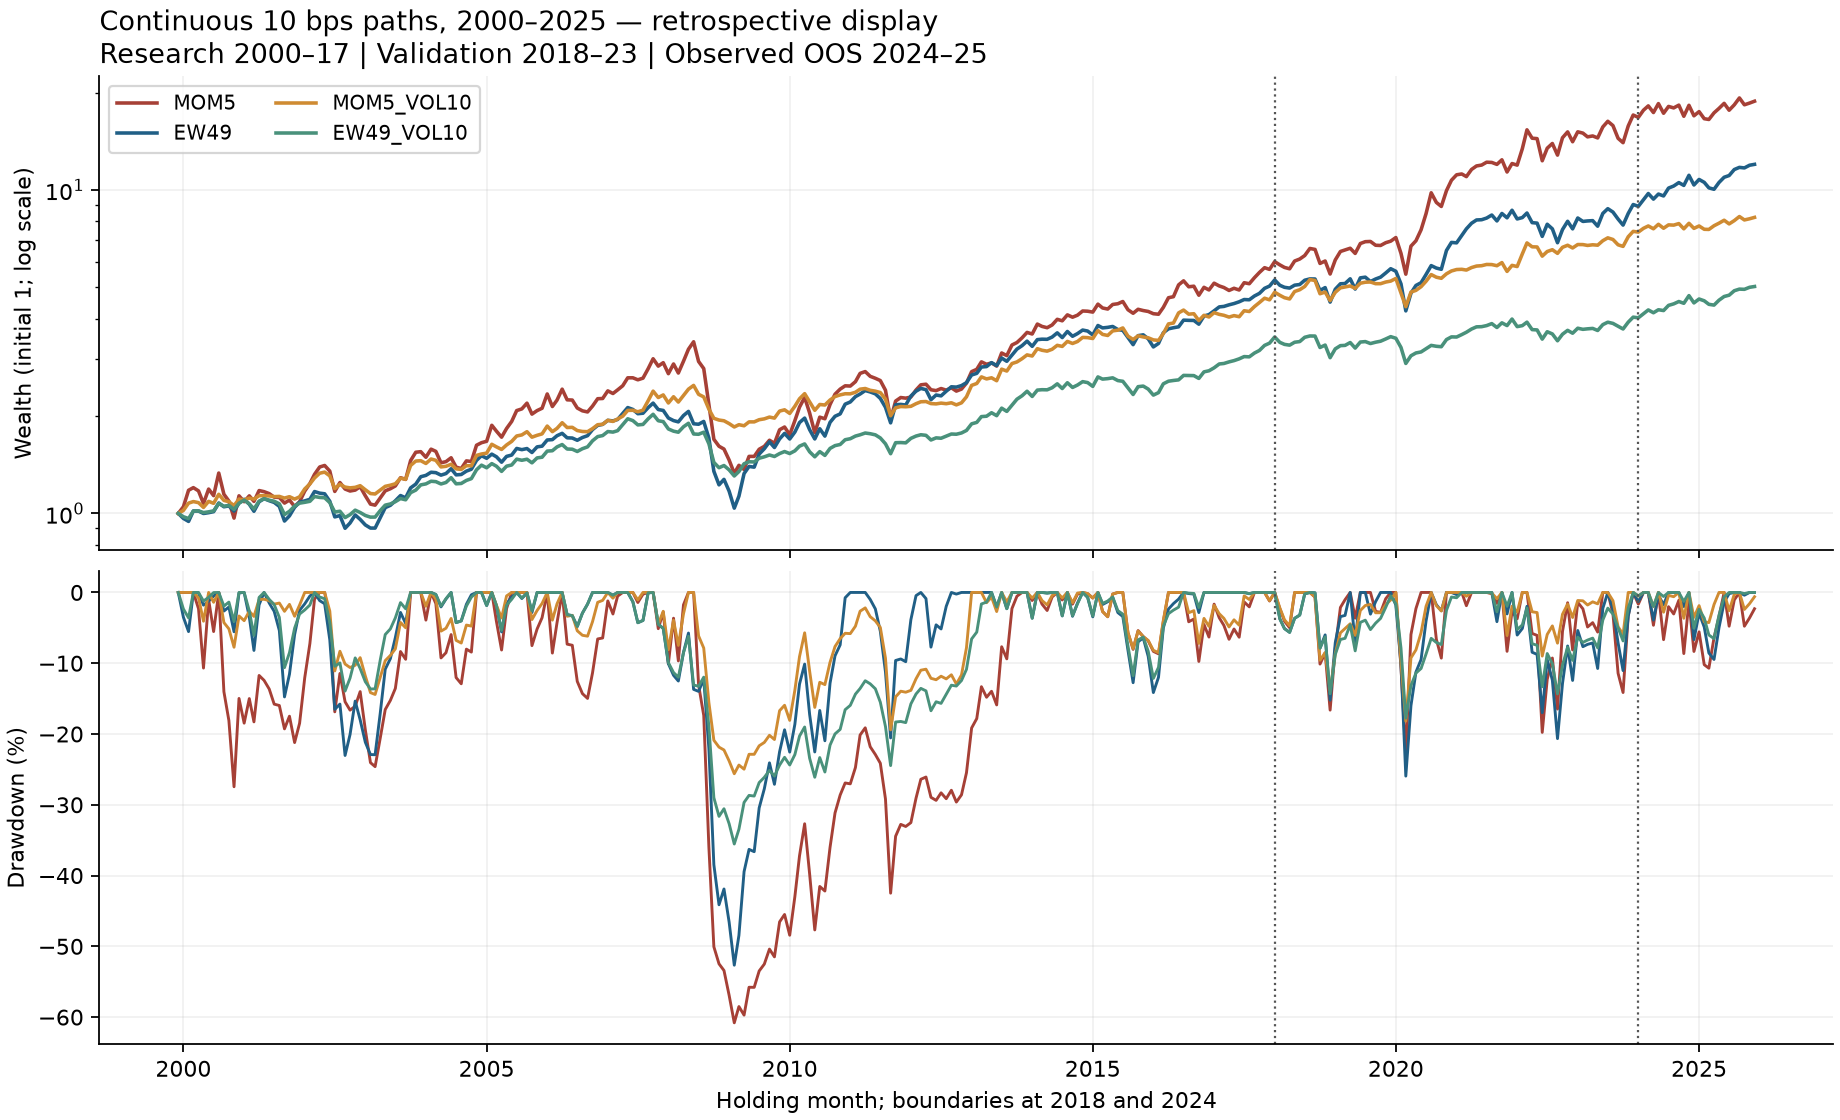

In [3]:
figure_dir = "reports/figures/day6_release"
figure_name = "01_wealth_drawdown.png"
figure_manifest = MANIFESTS[figure_dir + "/presentation_manifest.json"]
figure_bytes = checked_bytes(figure_dir + "/" + figure_name, figure_manifest["outputs"][figure_name]["sha256"])
display(Image(data=figure_bytes, width=1000))


## Accepted uncertainty estimates — no inference is fitted here

Rank IC compares the industry signal with its **same holding month's** realized return, using average ranks for ties. Stored intervals use an explicit-intercept model with Bartlett HAC(6), no small-sample correction and estimate ± 1.96 SE. The unit of IC inference is a month.

FF3+Mom attribution regresses net portfolio return minus RF on Mkt-RF, SMB, HML and Mom, with an intercept. RF is subtracted once. The displayed alpha is the stored **12 × monthly intercept**, an arithmetic annualization, not CAGR or causal alpha. Intervals include zero in the three IC summaries and four main-cost OOS intercepts: current evidence is insufficient to rule out a zero mean/intercept. **24 OOS months are exploratory and have limited statistical power**; zero inclusion does not prove that momentum never works.


In [4]:
ic_rows = accepted_csv("day4", "ic_hac.csv") + accepted_csv("day5", "ic_hac.csv")
ic_display = [[r["segment"], r["valid_months"], r["undefined_months"], f"{float(r['mean']):.6f}", f"[{float(r['ci_low']):.6f}, {float(r['ci_high']):.6f}]"] for r in ic_rows]
table(["Segment", "Valid months", "Undefined months", "Mean rank IC", "95% HAC interval"], ic_display)
alpha_rows = accepted_csv("day5", "factor_regressions.csv")
alpha_display = []
for strategy in STRATEGIES:
    row = next(r for r in alpha_rows if r["strategy"] == strategy and r["cost_bps"] == "10" and r["coefficient"] == "alpha")
    alpha_display.append([strategy, row["n_months"], pct(row["alpha_annual_arithmetic"]), f"[{pct(row['alpha_ci_low_annual'])}, {pct(row['alpha_ci_high_annual'])}]"])
table(["OOS portfolio", "Months", "Arithmetic annual alpha", "95% HAC interval"], alpha_display)


Segment,Valid months,Undefined months,Mean rank IC,95% HAC interval
research,216,0,0.030308,"[-0.006967, 0.067583]"
validation,72,0,0.026182,"[-0.019560, 0.071925]"
oos,24,0,0.007453,"[-0.050245, 0.065152]"


OOS portfolio,Months,Arithmetic annual alpha,95% HAC interval
MOM5,24,-5.6981%,"[-24.7599%, 13.3637%]"
EW49,24,-1.1900%,"[-5.4168%, 3.0367%]"
MOM5_VOL10,24,-3.2680%,"[-13.0508%, 6.5148%]"
EW49_VOL10,24,-1.1192%,"[-4.9757%, 2.7373%]"


## Timing example — dates only, not recalculated signals

For a January 2024 holding, 12–2 momentum compounds **eleven** industry returns, skipping December. Risk uses **twelve** prior unscaled base portfolio returns and therefore includes December. Updating risk with t−1 is compatible with skipping that month in momentum.

Historical base returns use the portfolio selected in each historical month. They are neither today's selected industries backfilled through history nor recursively scaled/net returns. January's realized industry return and RF do not choose January's weight. This idealized monthly ordering does not establish publication-lag feasibility or historical point-in-time availability.


In [5]:
signal_months = [f"2023-{m:02d}" for m in range(1, 12)]
risk_months = [f"2023-{m:02d}" for m in range(1, 13)]
assert len(signal_months) == 11 and signal_months[-1] == "2023-11"
assert len(risk_months) == 12 and risk_months[-1] == "2023-12"
table(["Holding month", "Purpose", "Source months", "Count"], [
    ["2024-01", "Momentum", ", ".join(signal_months), len(signal_months)],
    ["2024-01", "Risk", ", ".join(risk_months), len(risk_months)],
])


Holding month,Purpose,Source months,Count
2024-01,Momentum,"2023-01, 2023-02, 2023-03, 2023-04, 2023-05, 2023-06, 2023-07, 2023-08, 2023-09, 2023-10, 2023-11",11
2024-01,Risk,"2023-01, 2023-02, 2023-03, 2023-04, 2023-05, 2023-06, 2023-07, 2023-08, 2023-09, 2023-10, 2023-11, 2023-12",12


## SYNTHETIC — teaching example, not project results: exact fees

Let b be drifted industry weights before trading, w the intended weights in **post-cost** wealth, and c the one-way fee. Retained wealth k solves `k = 1 − c Σ|k w_i − b_i|`. Gross traded fraction D includes buys **and** sells, with no division by two; cash is not separately charged.

Starting entirely in cash and choosing risky share a gives D = k·a, hence **k = 1/(1+c·a)**. The familiar 1/(1+c) applies only when a = 1. A complete rotation from asset A to B has D = 1+k and k = (1−c)/(1+c). These are Decimal closed-form examples, not calls to project accounting code.


In [6]:
from decimal import Decimal, localcontext
with localcontext() as context:
    context.prec = 40
    one, c = Decimal(1), Decimal("0.001")
    fee_examples = []
    for a in [Decimal("1"), Decimal("0.6")]:
        k = one / (one + c * a)
        D = k * a
        assert abs(k + c * D - one) < Decimal("1e-38")
        assert abs(k * a + k * (one - a) + c * D - one) < Decimal("1e-38")
        fee_examples.append(["Cash to risky share " + str(a), f"{k:.12f}", f"{D:.12f}", f"{c*D:.12f}"])
    k = (one - c) / (one + c)
    D = one + k
    assert abs(k + c * D - one) < Decimal("1e-38")
    fee_examples.append(["100% A to 100% B", f"{k:.12f}", f"{D:.12f}", f"{c*D:.12f}"])
table(["SYNTHETIC case", "Retained wealth k", "Gross traded fraction D", "Cost fraction cD"], fee_examples)
print("SYNTHETIC self-financing identities passed; D has not been halved.")


SYNTHETIC case,Retained wealth k,Gross traded fraction D,Cost fraction cD
Cash to risky share 1,0.999000999001,0.999000999001,0.000999000999
Cash to risky share 0.6,0.999400359784,0.599640215870,0.000599640216
100% A to 100% B,0.998001998002,1.998001998002,0.001998001998


SYNTHETIC self-financing identities passed; D has not been halved.


## SYNTHETIC — teaching example, not project results: risk scaling

The next twelve numbers are invented unscaled monthly base returns, solely to illustrate sample standard deviation (`ddof=1`), annualization by √12, exposure capped at one, and residual cash. They are not French data or accepted portfolio performance. They represent a completed past window, not the holding month's outcome.

Six −0.04 and six +0.04 have mean zero and a hand-checkable sum of squares `12 × 0.04²`. Thus sample variance is `12 × 0.04² / 11`. The 10% rule is an exposure control, not a guarantee of realized volatility.


In [7]:
import math
import statistics
synthetic_base = [-0.04, 0.04] * 6
sigma = statistics.stdev(synthetic_base) * math.sqrt(12)
expected_sigma = math.sqrt((12 * 0.04**2 / 11) * 12)
assert len(synthetic_base) == 12 and sigma > 0
assert math.isclose(sigma, expected_sigma, rel_tol=0, abs_tol=1e-15)
a = min(1.0, 0.10 / sigma)
assert 0 <= a <= 1 and math.isclose(a + (1 - a), 1.0)
assert min(1.0, 0.10 / 0.05) == 1.0  # cap check, also synthetic
zero_sigma_exposure = 1.0  # frozen zero-volatility convention
assert zero_sigma_exposure == 1.0
table(["SYNTHETIC annual sigma", "Risky share", "Cash share"], [[f"{sigma:.8f}", f"{a:.8f}", f"{1-a:.8f}"]])
print("SYNTHETIC sample-variance and cap checks passed.")


SYNTHETIC annual sigma,Risky share,Cash share
0.14472545,0.69096350,0.30903650


SYNTHETIC sample-variance and cap checks passed.


## What the accepted study can and cannot establish

Industry returns are value weighted **within** each industry; the selected industry allocations are equal weighted **between** industries. The strategy is long-only and fully allocated before VOL scaling, even if every momentum score is negative. Cash earns same-month RF as realized income. Exact initial costs are charged in 2000, with no reset at 2018/2024 and no terminal liquidation.

Data are a revised current vintage, not full historical PIT. Industry research portfolios are not directly tradable ETFs. Assumed allocation costs omit internal turnover, market impact, capacity and taxes. Five-group Q5−Q1 is a gross diagnostic, not a net tradable long–short strategy. The two prespecified sensitivities are research/validation-only and were never added to OOS.

The weak final momentum comparison is retained. Lower risk exposure is not alpha; neither wide intervals nor a short final sample justify a search for a replacement winner. [Sources and permissions](../docs/DATA_SOURCES.md) remain separate from research acceptance.


In [8]:
table(["Accepted input read by this notebook", "SHA-256"], sorted(VERIFIED.items()))
print("Read-only display complete. No production functions, raw/processed reads, downloads or formal OOS runs.")


Accepted input read by this notebook,SHA-256
outputs/day4/ic_hac.csv,bedfb07d6419d6a67c040e1630fa8b1ca77c46462450e924a525cce99a991e8b
outputs/day4/performance_summary.csv,36c7d07262a182cf38bf07b4ee185dd4c1e6115c14af615c7258d0f8e371ad43
outputs/day4/run_manifest.json,8e3f587d0aa1f575fd18f920264aaeea38a0064257cabd9ee047a223665da461
outputs/day5/factor_regressions.csv,7484a1159bc787a531414612ab1eb85a103bcea6cfe5b2a0e82779719a7bf8a2
outputs/day5/ic_hac.csv,8f3300a213bba35121b6a6fe462f9917006335dc23905d378682384a946d250b
outputs/day5/performance_summary.csv,e019bdb0d3875349d3e3c53651b262a065b9ec191c085396f67f817b4a4f0502
outputs/day5/run_manifest.json,2fef4ac6f524291898dafa4e7febe405eaa5369bb3a7a6ac741f0a71f87b6998
reports/figures/day6_release/01_wealth_drawdown.png,5b964f6f39a9aff88b31c31d91ce4a79cb1de3342fc8e469461f72bfdc58cbd8
reports/figures/day6_release/presentation_manifest.json,af87d049d9046aa9a14838bd0f31f9b1de78bbd1c33e3ead782d5e5f0105a5b4


Read-only display complete. No production functions, raw/processed reads, downloads or formal OOS runs.


## Reproduction scope

Earlier private verification rebuilt raw→processed and reproduced fixed results through 2023 against preseeded references in a clean dependency environment on the same Mac. It was not an empty-output or cross-machine reproduction of all 2000–2025 results. The final interval has already been observed; two historical formal runs exist, and no new formal OOS run is part of this demo.

This public presentation uses three explicitly labeled **public display derivative manifests**, not original frozen manifest bytes. Only source identities, links and status wording changed; financial summary values and the accepted figure did not. [Source map](../PUBLIC_SOURCE_MAP.json) · [Reproduction limits](../docs/REPRODUCIBILITY.md) · [Demo instructions](../tools/walkthrough/README.md)

The runner requires pinned inputs, a fresh kernel and a new external output; it never downloads data or invokes production. Its executed Notebook is a private run artifact. The [Synthetic demo guards workflow](https://github.com/lapsapbin/AlphaLabSprintV1/actions/workflows/demo-ci.yml) records actual remote status. Publication is not authorization to rerun the final test.
